# FCTD / CTD figure

In [13]:
import matplotlib.pyplot as plt
import nescafe23 as n23
from matplotlib import gridspec
import xarray
import cmocean

%load_ext autoreload
%autoreload 2
%config InlineBackend.figure_format = 'retina'

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [15]:
whoi_colors = ['#00B7BD', '#EE5340', '#0069b1', '#041e42']

In [7]:
fctd = n23.compute_filtered_fctd_grid(r_smooth=None, z_smooth=None)
sioe_ctd = n23.open_sioe_ctd()
sion_ctd = n23.open_sion_ctd()

/Users/john/Code/NESCAFE/NESCAFE23/.venv/lib/python3.13/site-packages/xarray/computation/apply_ufunc.py:820: RuntimeWarning: invalid value encountered in sqrt
  result_data = func(*input_data)


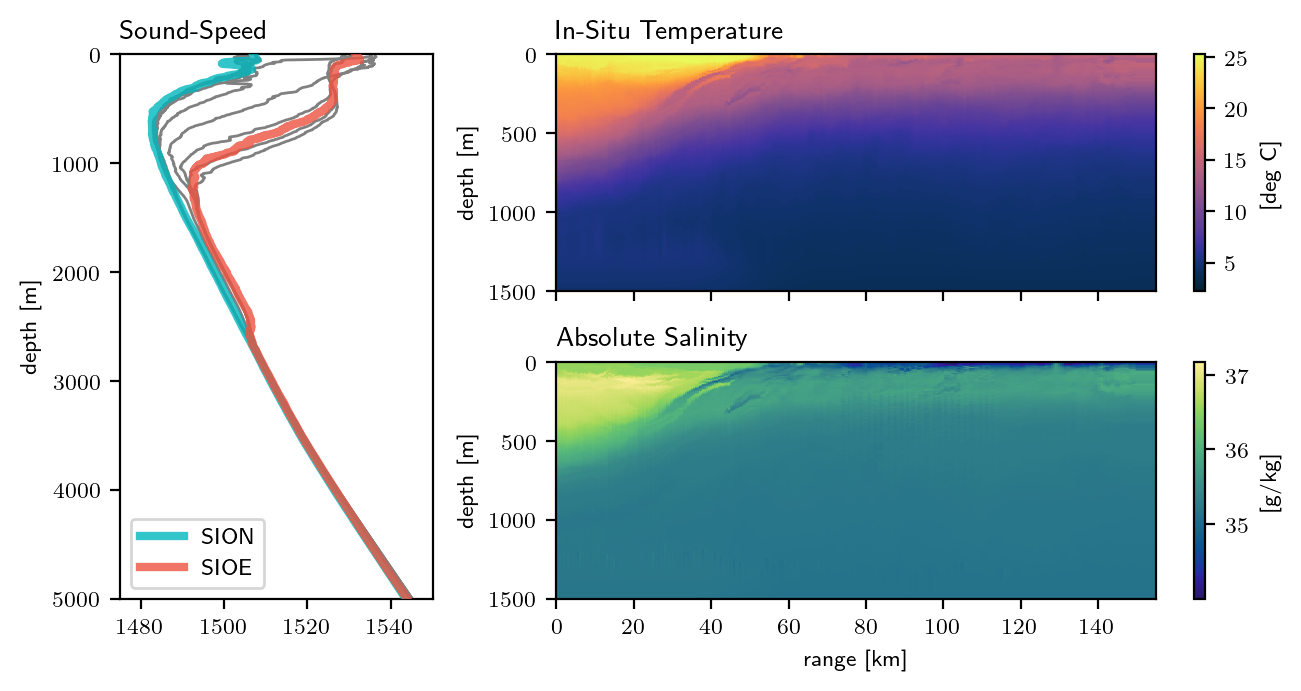

In [25]:
plt.rcParams.update({'font.size':8})
plt.rcParams["text.usetex"] = True
fig = plt.figure(figsize=(6.67, 3.5))
gs = gridspec.GridSpec(2,3)

ax_ctd = fig.add_subplot(gs[:,0])

ax_fctd_temp = fig.add_subplot(gs[0,1:])
ax_fctd_sal = fig.add_subplot(gs[1,1:])

# FCTD temp
plt.sca(ax_fctd_temp)
fctd['t'].assign_coords({'range':fctd.range/1000 + 35}).plot(x='range', cmap=cmocean.cm.thermal, cbar_kwargs={'label':'[deg C]'}, rasterized=True)
plt.ylim([1500,0])
plt.xlim([0, 155])
plt.xlabel('')
plt.ylabel('depth [m]')
plt.title('In-Situ Temperature', loc='left')
ax_fctd_temp.set_xticklabels([])

plt.sca(ax_fctd_sal)
fctd['SA'].assign_coords({'range':fctd.range/1000 + 35}).plot(x='range', cmap=cmocean.cm.haline, cbar_kwargs={'label':'[g/kg]'}, rasterized=True)
plt.ylim([1500,0])
plt.xlim([0, 155])
plt.xlabel('range [km]')
plt.ylabel('depth [m]')
plt.title('Absolute Salinity', loc='left')


plt.sca(ax_ctd)
plt.plot(sion_ctd['c'], sion_ctd.depth, lw=3, c=whoi_colors[0], zorder=100, alpha=0.8, label='SION')
plt.plot(sioe_ctd['c'], sioe_ctd.depth, lw=3, c=whoi_colors[1], zorder=100, alpha=0.8, label='SIOE')
plt.plot(fctd['c'][:,::50], fctd.depth, c='gray', lw=1)
plt.ylim([5000,0])
plt.xlim([1475, 1550])
plt.ylabel('depth [m]')
plt.title('Sound-Speed', loc='left')
plt.legend(loc='lower left')

plt.tight_layout()
fig.savefig("../../figures/CTD_FCTD.pdf", dpi=400)